In [1]:
# !pip install pandas

In [1]:
import pandas as pd
df = pd.read_csv("../data/bbc_news_articles.csv")

df.iloc[1]["content"]

'The Duke and Duchess of Sussex are calling for stronger protections for children from the dangers of social media, saying "enough is not being done".\n\nPrince Harry and Meghan are unveiling a memorial in New York City they say is dedicated to children who have died due to the harms of the internet.\n\n"We want to make sure that things are changed so that... no more kids are lost to social media," Prince Harry told BBC Breakfast in New York.\n\n"Life is better off social media," he said, adding he was "grateful" that his and Meghan\'s children were still too young to be online.\n\n"The easiest thing to say is to keep your kids away from social media. The sad reality is the kids who aren\'t on social media normally get bullied at school because they can\'t be part of the same conversation as everybody else," Prince Harry told journalists at an Archwell Foundation event in New York.\n\nThe installation unveiled by Prince Harry and Meghan is called the Lost Screen Memorial, and is made f

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 335 entries, 0 to 334
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   headline       335 non-null    object
 1   description    335 non-null    object
 2   section        284 non-null    object
 3   content_topic  303 non-null    object
 4   authors        293 non-null    object
 5   published      314 non-null    object
 6   modified       314 non-null    object
 7   image_url      335 non-null    object
 8   thumbnail_url  318 non-null    object
 9   main_entity    293 non-null    object
 10  content        293 non-null    object
 11  url            335 non-null    object
dtypes: object(12)
memory usage: 31.5+ KB


In [4]:
df.head()

,headline,description,section,content_topic,authors,published,modified,image_url,thumbnail_url,main_entity,content,url
0,Why Zelensky can't and won't give up Crimea,Ukraine's leader has ruled out recognising Rus...,Europe,"War in Ukraine, Volodymyr Zelensky, Russia, Cr...",Paul Kirby,2025-04-24 14:40:31.465000+00:00,2025-04-24T14:40:31.465Z,https://ichef.bbci.co.uk/news/1024/branded_new...,https://ichef.bbci.co.uk/news/1024/branded_new...,https://www.bbc.com/news/articles/cm2x58m46e1o,Vladimir Putin initially denied having anythin...,https://www.bbc.com/news/articles/cm2x58m46e1o
1,Harry and Meghan call for stronger social medi...,"They told the BBC they want to ensure ""no more...",Technology,"Social media, UK Royal Family, Meghan, Duchess...",Sean Coughlan,2025-04-24 14:00:15.875000+00:00,2025-04-24T14:00:15.875Z,https://ichef.bbci.co.uk/news/1024/branded_new...,https://ichef.bbci.co.uk/news/1024/branded_new...,https://www.bbc.com/news/articles/cjewne81lq4o,The Duke and Duchess of Sussex are calling for...,https://www.bbc.com/news/articles/cjewne81lq4o
2,UK edges towards post-Brexit youth visa deal w...,An agreement has emerged as a key European dem...,Europe,"European Union, Brexit",Paul Seddon,2025-04-24 13:11:18.051000+00:00,2025-04-24T13:11:18.051Z,https://ichef.bbci.co.uk/news/1024/branded_new...,https://ichef.bbci.co.uk/news/1024/branded_new...,https://www.bbc.com/news/articles/c9qw58r0x0do,The government is no longer ruling out a youth...,https://www.bbc.com/news/articles/c9qw58r0x0do
3,Student killed in French school stabbing attac...,At least three people were injured in the atta...,Europe,"Europe, France",BBC News,2025-04-24 12:41:38.852000+00:00,2025-04-24T13:32:23.198Z,https://ichef.bbci.co.uk/news/1024/branded_new...,https://ichef.bbci.co.uk/news/1024/branded_new...,https://www.bbc.com/news/articles/c787r15xngyo,One student has been killed and at least three...,https://www.bbc.com/news/articles/c787r15xngyo
4,Iceberg tracks found off UK coast could shed l...,Deep tracks gouged in the seafloor off the coa...,Climate,"Antarctic, Science & Environment, Glaciers, Cl...",Mark Poynting and Georgina Rannard,2025-04-24 09:00:09.196000+00:00,2025-04-24T09:00:09.196Z,https://ichef.bbci.co.uk/news/1024/branded_new...,https://ichef.bbci.co.uk/news/1024/branded_new...,https://www.bbc.com/news/articles/cm2xz664r2do,"Icebergs as large as cities, potentially tens ...",https://www.bbc.com/news/articles/cm2xz664r2do


In [6]:
import pandas as pd

# make sure 'published' is a datetime dtype (with UTC)
df['modified'] = pd.to_datetime(df['modified'], utc=True)

# get earliest and latest
min_pub = df['modified'].min()
max_pub = df['modified'].max()

print(f"Crawled data date range: {min_pub} to {max_pub}")

Crawled data date range: 2024-08-20 11:35:33+00:00 to 2025-04-24 14:41:56.087000+00:00


In [4]:
# !pip install yfinance

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26620\2228548560.py:16: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_trump['month'] = df_trump['published'].dt.to_period('M')


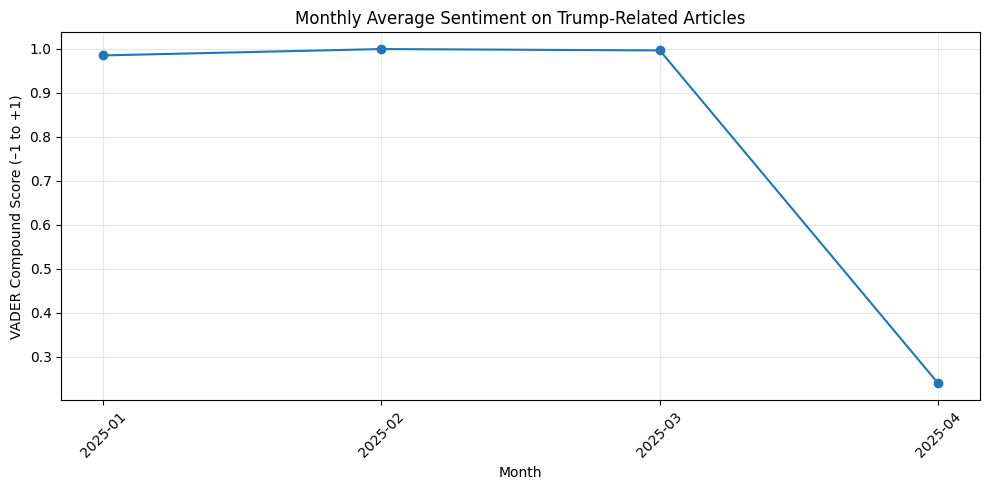

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

df = pd.read_csv('../data/bbc_news_articles.csv', parse_dates=['published'])

# 3. Filter các bài nói về Trump
mask = df['content'].str.contains(r'\bTrump\b', case=False, na=False)
df_trump = df.loc[mask].copy()

# 4. Chuẩn hoá datetime và nhóm theo tháng
df_trump['published'] = pd.to_datetime(df_trump['published'])
df_trump['month'] = df_trump['published'].dt.to_period('M')

# 5. Khởi tạo analyzer
sid = SentimentIntensityAnalyzer()

# 6. Tính sentiment compound cho mỗi bài
df_trump['sentiment'] = df_trump['content'] \
    .fillna('') \
    .apply(lambda txt: sid.polarity_scores(txt)['compound'])

# 7. Tính trung bình sentiment theo tháng
sentiment_monthly = df_trump.groupby('month')['sentiment'].mean().reset_index()

# 8. Vẽ line chart
plt.figure(figsize=(10, 5))
plt.plot(sentiment_monthly['month'].astype(str),
         sentiment_monthly['sentiment'],
         marker='o', linestyle='-')
plt.xticks(rotation=45)
plt.title("Monthly Average Sentiment on Trump-Related Articles")
plt.ylabel("VADER Compound Score (–1 to +1)")
plt.xlabel("Month")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:
# !pip install seaborn


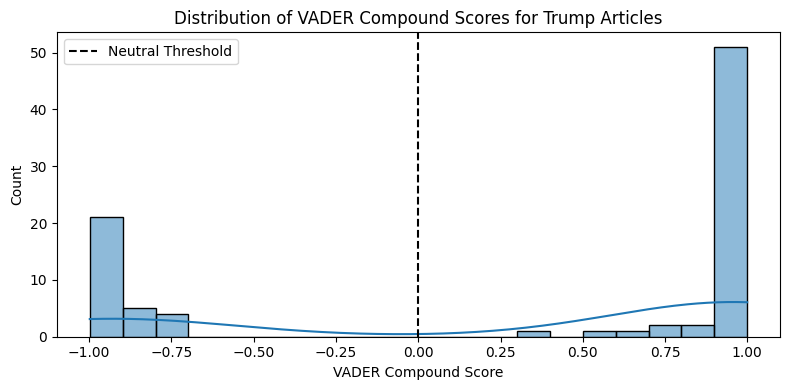

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
sns.histplot(df_trump['sentiment'], bins=20, kde=True)
plt.title("Distribution of VADER Compound Scores for Trump Articles")
plt.xlabel("VADER Compound Score")
plt.ylabel("Count")
plt.axvline(0, color='black', linestyle='--', label='Neutral Threshold')
plt.legend()
plt.tight_layout()
plt.show()


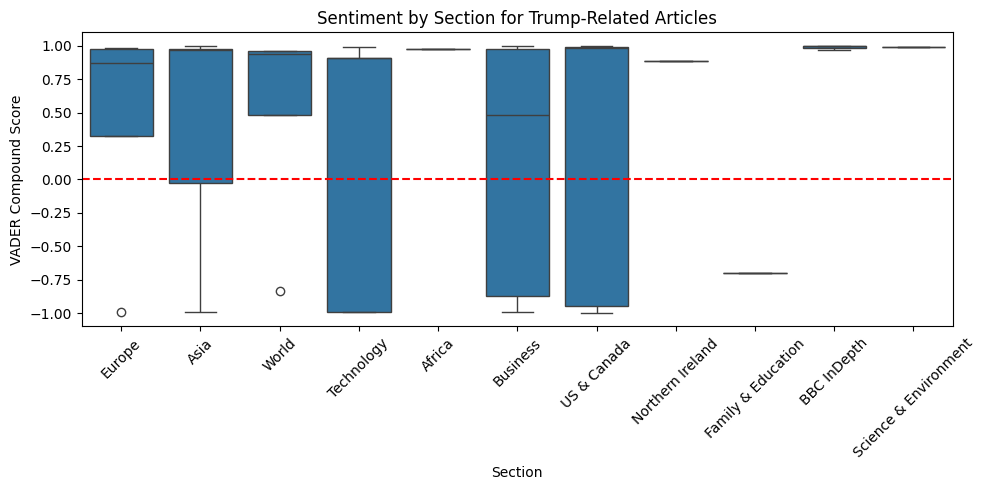

In [8]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_trump, x='section', y='sentiment')
plt.title("Sentiment by Section for Trump-Related Articles")
plt.xlabel("Section")
plt.ylabel("VADER Compound Score")
plt.xticks(rotation=45)
plt.axhline(0, color='red', linestyle='--')
plt.tight_layout()
plt.show()


In [9]:
# # Đảm bảo trend['month'] là str
# trend['month_str'] = trend['month'].astype(str)

# plt.figure(figsize=(10,5))
# sns.lineplot(
#     data=trend,
#     x='month_str',        # dùng đúng tên cột chuỗi
#     y='sentiment',
#     hue='section',
#     marker='o'
# )
# plt.title("Monthly Sentiment Trends by Section")
# plt.xlabel("Month")
# plt.ylabel("Avg VADER Compound Score")
# plt.xticks(rotation=45)
# plt.legend(title='Section')
# plt.tight_layout()
# plt.show()


Topic 0: said, trade, government, president, tariffs, house, white, world
Topic 1: said, china, tariffs, ukraine, president, apple, russia, chinese
Topic 2: said, uk, trade, tariffs, says, deal, housing, canada
Topic 3: said, musk, energy, tesla, space, china, trade, mr
Topic 4: canada, election, government, carney, party, climate, oil, said
Topic 5: china, rare, earths, minerals, beijing, critical, canada, says


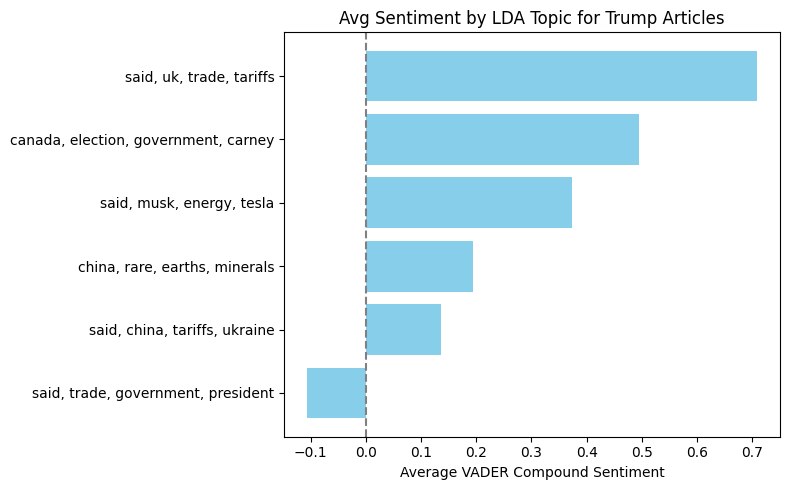

In [10]:
# Áp dụng topic modeling kết hợp sentiment để xác định chính sách nào (trade, crypto, tariffs…) gắn với cảm xúc tiêu cực hay tích cực nhất.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Chỉ lấy những bài không rỗng
docs = df_trump['content'].fillna('').tolist()

# 2) Vectorize với Bag-of-Words -------------------------------------------

vectorizer = CountVectorizer(
    max_df=0.95,   # loại bỏ từ quá phổ biến
    min_df=2,      # tối thiểu xuất hiện 2 docs
    stop_words='english'
)
X = vectorizer.fit_transform(docs)

# 3) LDA topic modeling ---------------------------------------------------

n_topics = 6   # có thể thử 4,5,6… tăng giảm cho phù hợp
lda = LatentDirichletAllocation(
    n_components=n_topics,
    max_iter=10,
    random_state=42
)
lda.fit(X)

# In ra top words của mỗi topic
feature_names = vectorizer.get_feature_names_out()
n_top_words = 8
topic_keywords = {}
for topic_idx, comp in enumerate(lda.components_):
    top_idx = np.argsort(comp)[-n_top_words:][::-1]
    words = [feature_names[i] for i in top_idx]
    topic_keywords[topic_idx] = words
    print(f"Topic {topic_idx}: {', '.join(words)}")

# 4) Gán topic chính cho từng doc ----------------------------------------

# Lấy ma trận topic distribution [n_docs, n_topics]
doc_topic_distr = lda.transform(X)

# Với mỗi bài chọn topic có trọng số cao nhất
dominant_topics = np.argmax(doc_topic_distr, axis=1)
df_trump['dominant_topic'] = dominant_topics

# 5) Tính trung bình sentiment theo topic -------------------------------

topic_sentiment = (
    df_trump
    .groupby('dominant_topic')['sentiment']
    .mean()
    .reset_index()
    .rename(columns={'sentiment':'avg_sentiment'})
)

# Thêm cột label là chuỗi keywords
topic_sentiment['keywords'] = topic_sentiment['dominant_topic'].apply(
    lambda t: ', '.join(topic_keywords[t][:4])  # lấy 4 từ đầu làm nhãn
)

# 6) Vẽ bar chart ---------------------------------------------------------

plt.figure(figsize=(8,5))
# Sắp xếp theo avg_sentiment để dễ so sánh
topic_sentiment = topic_sentiment.sort_values('avg_sentiment')
plt.barh(
    topic_sentiment['keywords'],
    topic_sentiment['avg_sentiment'],
    color='skyblue'
)
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel("Average VADER Compound Sentiment")
plt.title("Avg Sentiment by LDA Topic for Trump Articles")
plt.tight_layout()
plt.show()


In [11]:
# !pip install scikit-learn

In [12]:
# !pip install wordcloud

In [13]:
import pandas as pd
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt


# 2) Lọc các bài liên quan Trump và tính sentiment
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')
sid = SentimentIntensityAnalyzer()
df['sentiment'] = df['content'].fillna('').apply(lambda t: sid.polarity_scores(t)['compound'])
df_trump = df[df['content'].str.contains(r'\bTrump\b', case=False, na=False)].copy()

# 3) Lấy top 10 tiêu cực và tích cực
neg10 = df_trump.nsmallest(10, 'sentiment')[['headline', 'content']]
pos10 = df_trump.nlargest(10, 'sentiment')[['headline', 'content']]

# 4) Hiển thị
print("=== Top 10 Negative Trump-Related Articles ===")
for idx, row in neg10.iterrows():
    print(f"- {row['headline']}\n  {row['content']}...\n")

print("\n=== Top 10 Positive Trump-Related Articles ===")
for idx, row in pos10.iterrows():
    print(f"- {row['headline']}\n  {row['content']}...\n")


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


=== Top 10 Negative Trump-Related Articles ===
- Anxiety on US college campuses as foreign students deported
  For the last few weeks, many foreign students living in the US have watched as a sequence of events has repeated itself on their social media feeds: plain-clothes agents appearing unannounced and hauling students off in unmarked cars to detention centres.

Those taken into custody in a string of high-profile student detentions captured on video have not faced any criminal charges and instead appear to have been targeted for involvement in pro-Palestinian protests on college campuses.

The Trump administration has said repeatedly that visas are a "privilege" and can be revoked at any time fora wide variety of reasons.

But the crackdown appears to be far wider than initially thought, with more than 1,000 international students or recent graduates at colleges across the US now having had their visas revoked or legal statuses changed, according to a tracker from Inside Higher Ed,

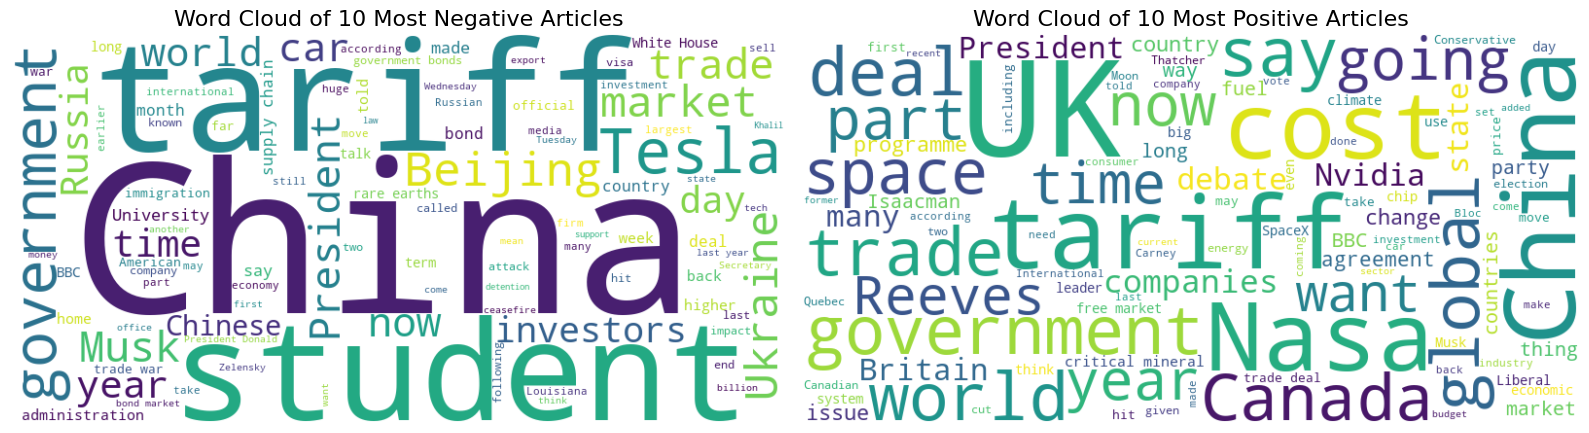

In [14]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# 1) Mở rộng stopwords
custom_stop = set(STOPWORDS)
custom_stop.update([
    'trump', 'said', 'would', 'also', 'one', 'new', 'us', 'us', 
    'mr', 'ms', 'will', 'people', 'can', 'could'
])

# 2) Gom text nhóm tiêu cực và tích cực
text_neg = " ".join(neg10['content'].fillna('').tolist())
text_pos = " ".join(pos10['content'].fillna('').tolist())

# 3) Tạo WordCloud với stopwords mới
wc_neg = WordCloud(
    width=800, height=400,
    background_color='white',
    stopwords=custom_stop,
    max_words=100
).generate(text_neg)

wc_pos = WordCloud(
    width=800, height=400,
    background_color='white',
    stopwords=custom_stop,
    max_words=100
).generate(text_pos)

# 4) Vẽ
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(wc_neg, interpolation='bilinear')
axes[0].set_title("Word Cloud of 10 Most Negative Articles", fontsize=16)
axes[0].axis('off')

axes[1].imshow(wc_pos, interpolation='bilinear')
axes[1].set_title("Word Cloud of 10 Most Positive Articles", fontsize=16)
axes[1].axis('off')

plt.tight_layout()
plt.show()


In [15]:
# !pip install pycountry

In [16]:
# !pip install plotly

In [17]:
import pandas as pd
import re
import pycountry
import plotly.express as px
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# 2) Lọc các bài liên quan đến Trump
df['content'] = df['content'].fillna('')
mask = df['content'].str.contains(r'\bTrump\b', case=False, na=False)
df_trump = df.loc[mask].copy()

# 3) Tính sentiment bằng VADER
nltk.download('vader_lexicon')
sid = SentimentIntensityAnalyzer()
df_trump['sentiment'] = df_trump['content'].apply(lambda t: sid.polarity_scores(t)['compound'])

# 4) Chuẩn bị mapping tên quốc gia → ISO3
countries = {c.name: c.alpha_3 for c in pycountry.countries}

# 5) Thu thập sentiment cho mỗi quốc gia được nhắc
country_sentiments = {}
for _, row in df_trump.iterrows():
    text = row['content']
    score = row['sentiment']
    for cname, iso in countries.items():
        if re.search(r'\b{}\b'.format(re.escape(cname)), text):
            country_sentiments.setdefault(iso, []).append(score)

# 6) Tính sentiment trung bình theo quốc gia
sent_data = [
    {'iso_alpha': iso, 'avg_sentiment': sum(vals) / len(vals)}
    for iso, vals in country_sentiments.items()
]
sent_df = pd.DataFrame(sent_data)

# 7) Vẽ bản đồ choropleth và lưu ra HTML
fig = px.choropleth(
    sent_df,
    locations='iso_alpha',
    color='avg_sentiment',
    color_continuous_scale='RdYlGn',
    range_color=[-1, 1],
    projection='natural earth',
    title='Average Sentiment on Trump-Related Articles by Country'
)
fig.update_layout(
    coloraxis_colorbar=dict(title="VADER Score"),
    margin=dict(l=0, r=0, t=50, b=0)
)

# Lưu file HTML
fig.write_html("trump_sentiment_world_map.html")
print("Map saved to trump_sentiment_world_map.html")


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Map saved to trump_sentiment_world_map.html


In [ ]:
import pandas as pd
import re
import pycountry
import plotly.express as px
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer


# 2) Lọc các bài liên quan đến Trump
df['content'] = df['content'].fillna('')
mask = df['content'].str.contains(r'\bTrump\b', case=False, na=False)
df_trump = df.loc[mask].copy()

# 3) Tính sentiment bằng VADER
nltk.download('vader_lexicon')
sid = SentimentIntensityAnalyzer()
df_trump['sentiment'] = df_trump['content'].apply(lambda t: sid.polarity_scores(t)['compound'])

# 4) Chuẩn bị mapping tên quốc gia → ISO3
countries = {c.name: c.alpha_3 for c in pycountry.countries}

# 5) Thu thập sentiment và headline cho mỗi quốc gia được nhắc
records = []
for _, row in df_trump.iterrows():
    text = row['content']
    score = row['sentiment']
    headline = row['headline']
    content= row['content']
    for cname, iso in countries.items():
        if re.search(r'\b{}\b'.format(re.escape(cname)), text):
            records.append({
                'iso_alpha': iso,
                'country': cname,
                'headline': headline,
                'content': content,
                'sentiment': score
            })

df_country = pd.DataFrame(records)

# 6) Tính sentiment trung bình theo quốc gia
sent_data = [
    {'iso_alpha': iso, 'avg_sentiment': sum(vals) / len(vals)}
    for iso, vals in df_country.groupby('iso_alpha')['sentiment'].apply(list).items()
]
sent_df = pd.DataFrame(sent_data)

# 7) Vẽ bản đồ choropleth và lưu ra HTML
fig = px.choropleth(
    sent_df,
    locations='iso_alpha',
    color='avg_sentiment',
    color_continuous_scale='RdYlGn',
    range_color=[-1, 1],
    projection='natural earth',
    title='Average Sentiment on Trump-Related Articles by Country'
)
fig.update_layout(
    coloraxis_colorbar=dict(title="VADER Score"),
    margin=dict(l=0, r=0, t=50, b=0)
)
fig.write_html("trump_sentiment_world_map.html")
print("Map saved to trump_sentiment_world_map.html")

# 8) Lấy top 3 bài tiêu cực nhất cho mỗi quốc gia
neg_by_country = (
    df_country[df_country['sentiment'] < 0]
    .groupby('iso_alpha')
    .apply(lambda grp: grp.nsmallest(3, 'sentiment'))
    .reset_index(drop=True)
)

# 9) Hiển thị danh sách
for iso, group in neg_by_country.groupby('iso_alpha'):
    print(f"\nCountry ISO3: {iso}")
    for _, row in group.iterrows():
        print(f"  • [{row['country']}] \"{row['headline']} \"{row['content'][:400]} \" (sentiment={row['sentiment']:.2f})")


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/ubuntu/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Map saved to trump_sentiment_world_map.html

Country ISO3: AUS
  • [Australia] "Five cards China holds in a trade war with the US "A trade war between the world's two biggest economies is now in full swing.

Chinese exports to the US face up to 245% tariffs, and Beijing has hit back with a 125% levy on American imports. Consumers, businesses and markets are braced for more uncertainty as fears of a global recession have heightened.

Chinese President Xi Jinping's government has repeatedly said it is open to dialogue, but warn " (sentiment=-0.99)
  • [Australia] "Five cards China holds in a trade war with the US "A trade war between the world's two biggest economies is now in full swing.

Chinese exports to the US face up to 245% tariffs, and Beijing has hit back with a 125% levy on American imports. Consumers, businesses and markets are braced for more uncertainty as fears of a global recession have heightened.

Chinese President Xi Jinping's government has repeatedly said it is open t

/tmp/ipykernel_251352/1805978964.py:71: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.

